# UNet & UNet++ — a reusable segmentation framework (PyTorch)

This notebook implements **UNet** (Ronneberger et al., MICCAI 2015) and **UNet++** (Zhou et al., DLMIA 2018 / IEEE TMI 2019, [arXiv:1807.10165](https://arxiv.org/abs/1807.10165)) from scratch and wraps them in a small framework that can be pointed at **any** image‑segmentation use case:

* binary or multi‑class masks,
* any folder of `images/` + `masks/` (paired by file name),
* GPU/CPU, mixed precision, early stopping, checkpoints,
* Dice / IoU evaluation, side‑by‑side visual comparison,
* UNet++ specifics: **dense nested skip pathways**, **deep supervision**, and **model pruning** at inference time (L1…L4).

As a worked example it trains both networks on **Kvasir‑SEG** (1,000 colonoscopy images with polyp masks; Jha et al., 2020, CC BY 4.0). If that dataset is not on disk the notebook downloads it (≈46 MB); if downloading is impossible it falls back to a synthetic‑shapes dataset so every cell still runs.

> **Why these two?** UNet is the canonical encoder–decoder with skip connections; UNet++ re‑designs the skips as a nested, densely connected pyramid so that encoder and decoder features are *semantically closer* before fusion, which the authors show improves Dice on several medical datasets. The 3D U‑Net with squeeze‑and‑excitation blocks used for hemorrhagic‑stroke lesion segmentation (Abramova et al., *Comput. Med. Imaging Graph.* 2021) is another UNet variant — the optional `use_se=True` switch below adds the same SE recalibration to every conv block.

## 0. Setup

In [1]:
import os, sys, time, math, random, json, zipfile, urllib.request, shutil
from pathlib import Path
from dataclasses import dataclass, asdict, field
from typing import Optional, List

import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt

torch.backends.cudnn.benchmark = True
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", DEVICE,
      f"({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else "")

def seed_everything(seed: int = 42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

torch 2.14.1+cu126 | device: cuda (NVIDIA GeForce RTX 4050 Laptop GPU)


## 1. Configuration — the only cell you need to edit for a new use case

| field | meaning |
|---|---|
| `images_dir`, `masks_dir` | folders with paired files (same stem, any extension) |
| `num_classes` | `1` → binary mask (sigmoid + BCE/Dice); `>1` → index mask PNG (softmax + CE/Dice) |
| `img_size` | training resolution (square); inference can run at any size |
| `use_se` | add squeeze‑and‑excitation to every conv block (UNet‑SE variant) |
| `deep_supervision` | UNet++ only: supervise all four decoder outputs X⁰ʲ |

In [2]:
@dataclass
class Config:
    # --- data -----------------------------------------------------------
    images_dir: str = "../data/kvasir_seg_download/Kvasir-SEG/images"
    masks_dir:  str = "../data/kvasir_seg_download/Kvasir-SEG/masks"
    out_dir:    str = "../outputs/unet_vs_unetpp"
    num_classes: int = 1            # 1 = binary, >1 = multi-class index masks
    mask_threshold: int = 127       # binary masks: pixel > threshold -> foreground
    img_size: int = 256
    val_fraction: float = 0.15
    max_images: Optional[int] = None   # subsample for quick experiments
    cache_in_ram: bool = True
    # --- model ----------------------------------------------------------
    base_channels: int = 32         # 32 -> [32, 64, 128, 256, 512]
    use_se: bool = False
    deep_supervision: bool = True   # UNet++ only
    # --- training -------------------------------------------------------
    epochs: int = 12
    batch_size: int = 16
    lr: float = 1e-3
    weight_decay: float = 1e-4
    patience: int = 5               # early stopping on val Dice
    amp: bool = True
    num_workers: int = 0            # keep 0 on Windows / in notebooks
    seed: int = 42

cfg = Config()
seed_everything(cfg.seed)
Path(cfg.out_dir).mkdir(parents=True, exist_ok=True)
print(json.dumps(asdict(cfg), indent=2))

{
  "images_dir": "../data/kvasir_seg_download/Kvasir-SEG/images",
  "masks_dir": "../data/kvasir_seg_download/Kvasir-SEG/masks",
  "out_dir": "../outputs/unet_vs_unetpp",
  "num_classes": 1,
  "mask_threshold": 127,
  "img_size": 256,
  "val_fraction": 0.15,
  "max_images": null,
  "cache_in_ram": true,
  "base_channels": 32,
  "use_se": false,
  "deep_supervision": true,
  "epochs": 12,
  "batch_size": 16,
  "lr": 0.001,
  "weight_decay": 0.0001,
  "patience": 5,
  "amp": true,
  "num_workers": 0,
  "seed": 42
}


## 2. Data

`SegmentationFolderDataset` pairs every image with the mask that shares its file stem, resizes both (bilinear for images, nearest for masks), and applies light augmentation (flips, 90° rotations, brightness/contrast jitter) on the training split only. Masks are returned as `float32 [1,H,W]` for binary problems and `int64 [H,W]` for multi‑class problems.

The `prepare_demo_dataset()` helper only runs when the configured folders are missing.

In [3]:
def prepare_demo_dataset(cfg: Config):
    '''Download Kvasir-SEG if needed; fall back to synthetic shapes if offline.'''
    if Path(cfg.images_dir).is_dir() and Path(cfg.masks_dir).is_dir():
        return
    root = Path(cfg.images_dir).parent.parent          # ../data/kvasir_seg_download
    root.mkdir(parents=True, exist_ok=True)
    url = "https://datasets.simula.no/downloads/kvasir-seg.zip"
    try:
        zpath = root / "kvasir-seg.zip"
        if not zpath.exists():
            print("Downloading Kvasir-SEG (46 MB) ...")
            urllib.request.urlretrieve(url, zpath)
        with zipfile.ZipFile(zpath) as z:
            assert not any(n.startswith("/") or ".." in n for n in z.namelist())
            z.extractall(root)
        print("Kvasir-SEG ready at", root / "Kvasir-SEG")
    except Exception as e:
        print("Download failed (", e, ") -> generating a synthetic shapes dataset instead")
        synth = Path("../data/synthetic_shapes"); (synth/"images").mkdir(parents=True, exist_ok=True); (synth/"masks").mkdir(exist_ok=True)
        rng = np.random.default_rng(0)
        for i in range(400):
            img = rng.integers(0, 60, (256, 256, 3), dtype=np.uint8) + rng.integers(0, 40)
            m = np.zeros((256, 256), np.uint8)
            yy, xx = np.mgrid[:256, :256]
            for _ in range(rng.integers(1, 4)):
                cy, cx, ry, rx = rng.integers(40, 216, 2).tolist() + rng.integers(15, 60, 2).tolist()
                blob = ((yy-cy)/ry)**2 + ((xx-cx)/rx)**2 <= 1
                m[blob] = 255; img[blob] = rng.integers(120, 255, 3)
            Image.fromarray(img).save(synth/"images"/f"{i:04d}.jpg"); Image.fromarray(m).save(synth/"masks"/f"{i:04d}.png")
        cfg.images_dir, cfg.masks_dir = str(synth/"images"), str(synth/"masks")

prepare_demo_dataset(cfg)

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def list_pairs(images_dir, masks_dir):
    masks = {p.stem: p for p in Path(masks_dir).iterdir() if p.suffix.lower() in IMG_EXT}
    pairs = [(p, masks[p.stem]) for p in sorted(Path(images_dir).iterdir()) if p.suffix.lower() in IMG_EXT and p.stem in masks]
    if not pairs: raise FileNotFoundError(f"No image/mask pairs found in {images_dir} / {masks_dir}")
    return pairs

class SegmentationFolderDataset(Dataset):
    def __init__(self, pairs, cfg: Config, train: bool):
        self.pairs, self.cfg, self.train = pairs, cfg, train
        self.cache = [None] * len(pairs) if cfg.cache_in_ram else None

    def __len__(self): return len(self.pairs)

    def _load(self, i):
        if self.cache is not None and self.cache[i] is not None: return self.cache[i]
        ip, mp = self.pairs[i]; s = self.cfg.img_size
        img = np.asarray(Image.open(ip).convert("RGB").resize((s, s), Image.BILINEAR), dtype=np.uint8)
        m = Image.open(mp)
        m = m.convert("L") if self.cfg.num_classes == 1 else m
        m = np.asarray(m.resize((s, s), Image.NEAREST))
        if self.cfg.num_classes == 1: m = (m > self.cfg.mask_threshold).astype(np.uint8)
        else: m = m.astype(np.int64)
        if self.cache is not None: self.cache[i] = (img, m)
        return img, m

    def __getitem__(self, i):
        img, m = self._load(i)
        img = img.astype(np.float32) / 255.0
        if self.train:                                   # geometric aug (shared) + photometric aug (image only)
            if random.random() < 0.5: img, m = img[:, ::-1], m[:, ::-1]
            if random.random() < 0.5: img, m = img[::-1], m[::-1]
            k = random.randint(0, 3); img, m = np.rot90(img, k), np.rot90(m, k)
            img = np.clip(img * random.uniform(0.8, 1.2) + random.uniform(-0.1, 0.1), 0, 1)
        img = torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1)
        img = (img - 0.5) / 0.5
        if self.cfg.num_classes == 1: m = torch.from_numpy(np.ascontiguousarray(m)).float().unsqueeze(0)
        else: m = torch.from_numpy(np.ascontiguousarray(m)).long()
        return img, m

pairs = list_pairs(cfg.images_dir, cfg.masks_dir)
if cfg.max_images: pairs = pairs[:cfg.max_images]
random.Random(cfg.seed).shuffle(pairs)
n_val = max(1, int(len(pairs) * cfg.val_fraction))
val_pairs, train_pairs = pairs[:n_val], pairs[n_val:]
train_ds, val_ds = SegmentationFolderDataset(train_pairs, cfg, True), SegmentationFolderDataset(val_pairs, cfg, False)
train_dl = DataLoader(train_ds, cfg.batch_size, shuffle=True, num_workers=cfg.num_workers, pin_memory=DEVICE=="cuda", drop_last=True)
val_dl   = DataLoader(val_ds, cfg.batch_size, shuffle=False, num_workers=cfg.num_workers, pin_memory=DEVICE=="cuda")
print(f"{len(pairs)} pairs -> train {len(train_ds)} / val {len(val_ds)}  | classes: {cfg.num_classes}  | size: {cfg.img_size}")

1000 pairs -> train 850 / val 150  | classes: 1  | size: 256


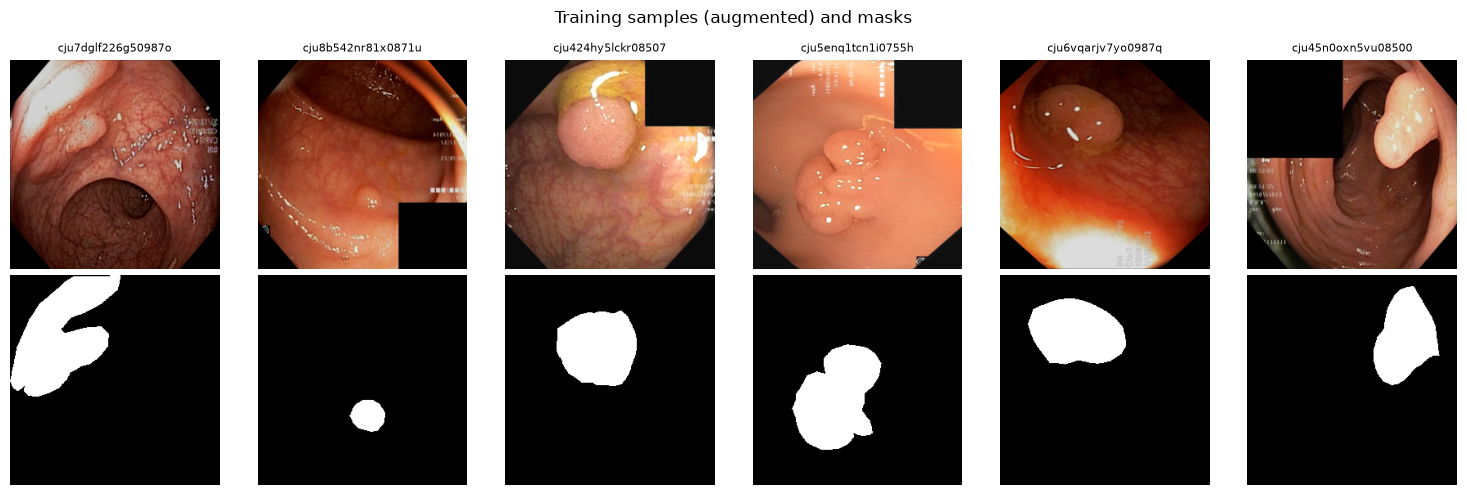

In [4]:
def denorm(x): return (x * 0.5 + 0.5).clamp(0, 1)

fig, ax = plt.subplots(2, 6, figsize=(15, 5))
for j in range(6):
    img, m = train_ds[j]
    ax[0, j].imshow(denorm(img).permute(1, 2, 0)); ax[0, j].set_title(train_pairs[j][0].name[:18], fontsize=8)
    ax[1, j].imshow(m.squeeze().numpy() if cfg.num_classes == 1 else m.numpy(), cmap="gray")
    for a in ax[:, j]: a.axis("off")
plt.suptitle("Training samples (augmented) and masks"); plt.tight_layout(); plt.show()

## 3. Models

### 3.1 Building blocks
`ConvBlock` = (Conv3×3 → BN → ReLU) × 2, optionally followed by a **squeeze‑and‑excitation** (SE) channel‑attention block (Hu et al., 2018) — the same recalibration used in the 3D U‑Net of Abramova et al. (2021).

In [5]:
class SEBlock(nn.Module):
    '''Squeeze-and-Excitation: global-pool -> FC -> ReLU -> FC -> sigmoid -> channel re-weighting.'''
    def __init__(self, ch, r=8):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(ch, max(ch // r, 4)), nn.ReLU(inplace=True), nn.Linear(max(ch // r, 4), ch), nn.Sigmoid())
    def forward(self, x):
        w = self.fc(x.mean((2, 3)))
        return x * w[:, :, None, None]

class ConvBlock(nn.Module):
    def __init__(self, cin, cout, use_se=False):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
        self.se = SEBlock(cout) if use_se else nn.Identity()
    def forward(self, x): return self.se(self.net(x))

def up2x(x): return F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)

### 3.2 UNet
Classic 4‑level encoder–decoder. Each decoder level upsamples, concatenates the encoder feature map at the same resolution (the *plain* skip connection) and applies a `ConvBlock`.

```
X0 ──────────────────────────── cat ── D0 ── 1×1 ── logits
 └ pool → X1 ──────────── cat ── D1 ──┘
           └ pool → X2 ── cat ── D2 ──┘
                     └ pool → X3 ─ cat ─ D3
                               └ pool → X4 (bottleneck)
```

In [6]:
class UNet(nn.Module):
    def __init__(self, in_ch=3, num_classes=1, base=32, use_se=False):
        super().__init__()
        f = [base, base*2, base*4, base*8, base*16]
        self.enc = nn.ModuleList([ConvBlock(in_ch if i == 0 else f[i-1], f[i], use_se) for i in range(5)])
        self.pool = nn.MaxPool2d(2)
        self.dec = nn.ModuleList([ConvBlock(f[i] + f[i+1], f[i], use_se) for i in range(4)])   # D3..D0
        self.head = nn.Conv2d(f[0], num_classes, 1)

    def forward(self, x):
        feats = []
        for i, blk in enumerate(self.enc):
            x = blk(x if i == 0 else self.pool(x)); feats.append(x)
        x = feats[4]
        for i in range(3, -1, -1):
            x = self.dec[i](torch.cat([feats[i], up2x(x)], 1))
        return self.head(x)

### 3.3 UNet++ (nested UNet)
Node $X^{i,j}$ sits at encoder depth $i$ and dense‑skip column $j$:

$$X^{i,j} = \mathcal{H}\big(\,[\,X^{i,0},\dots,X^{i,j-1},\ \mathrm{Up}(X^{i+1,j-1})\,]\,\big)$$

so every decoder node receives **all** previous nodes at the same resolution (dense connections, à la DenseNet) plus the upsampled node from one level down. This fills the semantic gap between encoder and decoder features that plain UNet skips leave open.

* **Deep supervision**: 1×1 heads on $X^{0,1},X^{0,2},X^{0,3},X^{0,4}$; the loss is averaged over the four outputs.
* **Pruning**: at inference you can stop at any column $L\in\{1,2,3,4\}$ (`model.forward(x, L=2)`) and get a faster, shallower network from the *same* trained weights.

In [7]:
class UNetPlusPlus(nn.Module):
    def __init__(self, in_ch=3, num_classes=1, base=32, use_se=False, deep_supervision=True):
        super().__init__()
        f = [base, base*2, base*4, base*8, base*16]
        self.ds = deep_supervision
        self.pool = nn.MaxPool2d(2)
        self.nodes = nn.ModuleDict()
        for i in range(5):                                   # backbone column j = 0
            self.nodes[f"{i}_0"] = ConvBlock(in_ch if i == 0 else f[i-1], f[i], use_se)
        for j in range(1, 5):                                # nested columns
            for i in range(0, 5 - j):
                cin = f[i] * j + f[i+1]                      # j same-level inputs + one upsampled input
                self.nodes[f"{i}_{j}"] = ConvBlock(cin, f[i], use_se)
        self.heads = nn.ModuleList([nn.Conv2d(f[0], num_classes, 1) for _ in range(4)])

    def forward(self, x, L: int = 4):
        '''L = number of nested columns to evaluate (1..4). Training with deep supervision returns a list.'''
        X = {}
        X["0_0"] = self.nodes["0_0"](x)
        for i in range(1, L + 1):
            X[f"{i}_0"] = self.nodes[f"{i}_0"](self.pool(X[f"{i-1}_0"]))
        for j in range(1, L + 1):
            for i in range(0, L + 1 - j):
                same = [X[f"{i}_{k}"] for k in range(j)]
                X[f"{i}_{j}"] = self.nodes[f"{i}_{j}"](torch.cat(same + [up2x(X[f"{i+1}_{j-1}"])], 1))
        outs = [self.heads[j-1](X[f"0_{j}"]) for j in range(1, L + 1)]
        if self.training and self.ds: return outs            # list -> deep supervision loss
        return outs[-1]                                      # inference: output of the deepest evaluated column

def count_params(m): return sum(p.numel() for p in m.parameters()) / 1e6

_u  = UNet(3, cfg.num_classes, cfg.base_channels, cfg.use_se)
_upp = UNetPlusPlus(3, cfg.num_classes, cfg.base_channels, cfg.use_se, cfg.deep_supervision)
with torch.no_grad():
    d = torch.zeros(1, 3, cfg.img_size, cfg.img_size)
    print(f"UNet    : {count_params(_u):.2f} M params | out {tuple(_u.eval()(d).shape)}")
    print(f"UNet++  : {count_params(_upp):.2f} M params | out {tuple(_upp.eval()(d).shape)}  | pruned L=1 out {tuple(_upp(d, L=1).shape)}")
del _u, _upp

UNet    : 7.85 M params | out (1, 1, 256, 256)


UNet++  : 9.16 M params | out (1, 1, 256, 256)  | pruned L=1 out (1, 1, 256, 256)


## 4. Loss & metrics
* **Binary**: BCE‑with‑logits + soft Dice.  **Multi‑class**: cross‑entropy + mean soft Dice over classes.
* Metrics (on hard predictions): Dice and IoU, averaged over images (binary) or over classes (multi‑class).

In [8]:
class SegLoss(nn.Module):
    def __init__(self, num_classes, dice_weight=1.0, eps=1e-6):
        super().__init__(); self.nc, self.w, self.eps = num_classes, dice_weight, eps
    def forward(self, logits, target):
        if isinstance(logits, (list, tuple)):             # deep supervision
            return sum(self(l, target) for l in logits) / len(logits)
        if self.nc == 1:
            bce = F.binary_cross_entropy_with_logits(logits, target)
            p = torch.sigmoid(logits)
            inter = (p * target).sum((1, 2, 3)); union = p.sum((1, 2, 3)) + target.sum((1, 2, 3))
            dice = 1 - ((2 * inter + self.eps) / (union + self.eps)).mean()
            return bce + self.w * dice
        ce = F.cross_entropy(logits, target)
        p = torch.softmax(logits, 1); oh = F.one_hot(target, self.nc).permute(0, 3, 1, 2).float()
        inter = (p * oh).sum((0, 2, 3)); union = p.sum((0, 2, 3)) + oh.sum((0, 2, 3))
        dice = 1 - ((2 * inter + self.eps) / (union + self.eps)).mean()
        return ce + self.w * dice

@torch.no_grad()
def hard_pred(logits, num_classes):
    return (logits > 0).long().squeeze(1) if num_classes == 1 else logits.argmax(1)

@torch.no_grad()
def dice_iou(pred, target, num_classes, eps=1e-6):
    '''Returns (dice, iou) averaged over the batch (binary) or over present classes (multi-class).'''
    if num_classes == 1:
        t = target.squeeze(1).long(); inter = (pred & t).sum((1, 2)).float(); ps, ts = pred.sum((1, 2)).float(), t.sum((1, 2)).float()
        dice = (2 * inter + eps) / (ps + ts + eps); iou = (inter + eps) / (ps + ts - inter + eps)
        return dice.mean().item(), iou.mean().item()
    ds, ious = [], []
    for c in range(num_classes):
        p, t = pred == c, target == c
        if t.sum() == 0 and p.sum() == 0: continue
        inter = (p & t).sum().float(); ps, ts = p.sum().float(), t.sum().float()
        ds.append(((2 * inter + eps) / (ps + ts + eps)).item()); ious.append(((inter + eps) / (ps + ts - inter + eps)).item())
    return float(np.mean(ds)), float(np.mean(ious))

## 5. Trainer
AdamW + one‑cycle LR, automatic mixed precision, early stopping on validation Dice, best‑checkpoint saving and a JSON history.

In [9]:
@torch.no_grad()
def evaluate(model, dl, criterion, cfg, L=4):
    model.eval(); tot, dices, ious, n = 0.0, [], [], 0
    for x, y in dl:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(DEVICE, enabled=cfg.amp and DEVICE == "cuda"):
            logits = model(x, L=L) if isinstance(model, UNetPlusPlus) else model(x)
            loss = criterion(logits, y)
        d, i = dice_iou(hard_pred(logits.float(), cfg.num_classes), y, cfg.num_classes)
        tot += loss.item() * x.size(0); dices.append(d * x.size(0)); ious.append(i * x.size(0)); n += x.size(0)
    return dict(loss=tot / n, dice=sum(dices) / n, iou=sum(ious) / n)

def train_model(model, name, cfg, train_dl, val_dl):
    model.to(DEVICE)
    criterion = SegLoss(cfg.num_classes)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg.lr, total_steps=cfg.epochs * len(train_dl), pct_start=0.15)
    scaler = torch.amp.GradScaler(DEVICE, enabled=cfg.amp and DEVICE == "cuda")
    hist, best, bad, ckpt = [], -1.0, 0, Path(cfg.out_dir) / f"{name}_best.pt"
    t0 = time.time()
    for ep in range(1, cfg.epochs + 1):
        model.train(); run, n, te = 0.0, 0, time.time()
        for x, y in train_dl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE, enabled=cfg.amp and DEVICE == "cuda"):
                loss = criterion(model(x), y)
            scaler.scale(loss).backward(); scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run += loss.item() * x.size(0); n += x.size(0)
        val = evaluate(model, val_dl, criterion, cfg)
        rec = dict(epoch=ep, train_loss=run / n, **{f"val_{k}": v for k, v in val.items()}, lr=sched.get_last_lr()[0], sec=time.time() - te)
        hist.append(rec)
        flag = ""
        if val["dice"] > best: best, bad, flag = val["dice"], 0, "  *saved*"; torch.save(model.state_dict(), ckpt)
        else: bad += 1
        print(f"[{name}] ep {ep:02d}/{cfg.epochs} train {rec['train_loss']:.4f} | val loss {val['loss']:.4f} dice {val['dice']:.4f} iou {val['iou']:.4f} | {rec['sec']:.0f}s{flag}")
        if bad >= cfg.patience: print(f"[{name}] early stopping (no val-Dice gain for {cfg.patience} epochs)"); break
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    json.dump(hist, open(Path(cfg.out_dir) / f"{name}_history.json", "w"), indent=1)
    print(f"[{name}] best val Dice {best:.4f} | total {time.time()-t0:.0f}s | checkpoint {ckpt}")
    return hist

## 6. Train UNet and UNet++ on the same split

In [10]:
seed_everything(cfg.seed)
unet = UNet(3, cfg.num_classes, cfg.base_channels, cfg.use_se)
hist_unet = train_model(unet, "unet", cfg, train_dl, val_dl)

[unet] ep 01/12 train 1.3162 | val loss 2.1559 dice 0.3893 iou 0.2705 | 82s  *saved*


[unet] ep 02/12 train 1.1311 | val loss 1.2106 dice 0.4652 iou 0.3339 | 14s  *saved*


[unet] ep 03/12 train 0.9704 | val loss 0.9128 dice 0.5071 iou 0.3906 | 14s  *saved*


[unet] ep 04/12 train 0.8860 | val loss 0.8412 dice 0.5248 iou 0.4040 | 14s  *saved*


[unet] ep 05/12 train 0.7805 | val loss 0.7551 dice 0.6026 iou 0.4785 | 14s  *saved*


[unet] ep 06/12 train 0.7256 | val loss 0.8041 dice 0.6099 iou 0.4795 | 14s  *saved*


... (2 outputs left out)

[unet] ep 09/12 train 0.5803 | val loss 0.5579 dice 0.7274 iou 0.6167 | 15s  *saved*


[unet] ep 10/12 train 0.5538 | val loss 0.5439 dice 0.7337 iou 0.6252 | 15s  *saved*


[unet] ep 11/12 train 0.5297 | val loss 0.5291 dice 0.7346 iou 0.6267 | 15s  *saved*


[unet] ep 12/12 train 0.5184 | val loss 0.5298 dice 0.7351 iou 0.6285 | 15s  *saved*
[unet] best val Dice 0.7351 | total 239s | checkpoint ..\outputs\unet_vs_unetpp\unet_best.pt


In [11]:
seed_everything(cfg.seed)
unetpp = UNetPlusPlus(3, cfg.num_classes, cfg.base_channels, cfg.use_se, cfg.deep_supervision)
hist_unetpp = train_model(unetpp, "unetpp", cfg, train_dl, val_dl)

[unetpp] ep 01/12 train 1.3395 | val loss 1.4277 dice 0.3743 iou 0.2571 | 81s  *saved*


[unetpp] ep 02/12 train 1.1707 | val loss 1.2070 dice 0.4518 iou 0.3206 | 52s  *saved*


[unetpp] ep 03/12 train 1.0633 | val loss 0.9799 dice 0.5083 iou 0.3762 | 53s  *saved*


[unetpp] ep 04/12 train 0.9886 | val loss 0.9122 dice 0.5382 iou 0.4012 | 54s  *saved*


[unetpp] ep 05/12 train 0.9430 | val loss 0.8169 dice 0.5712 iou 0.4465 | 55s  *saved*


[unetpp] ep 06/12 train 0.8936 | val loss 0.7958 dice 0.5987 iou 0.4715 | 53s  *saved*


... (2 outputs left out)

[unetpp] ep 09/12 train 0.7880 | val loss 0.5403 dice 0.7442 iou 0.6355 | 52s  *saved*


[unetpp] ep 10/12 train 0.7612 | val loss 0.5073 dice 0.7622 iou 0.6599 | 51s  *saved*


[unetpp] ep 11/12 train 0.7418 | val loss 0.4973 dice 0.7647 iou 0.6625 | 52s  *saved*


[unetpp] ep 12/12 train 0.7387 | val loss 0.4993 dice 0.7610 iou 0.6571 | 52s
[unetpp] best val Dice 0.7647 | total 658s | checkpoint ..\outputs\unet_vs_unetpp\unetpp_best.pt


## 7. Comparison

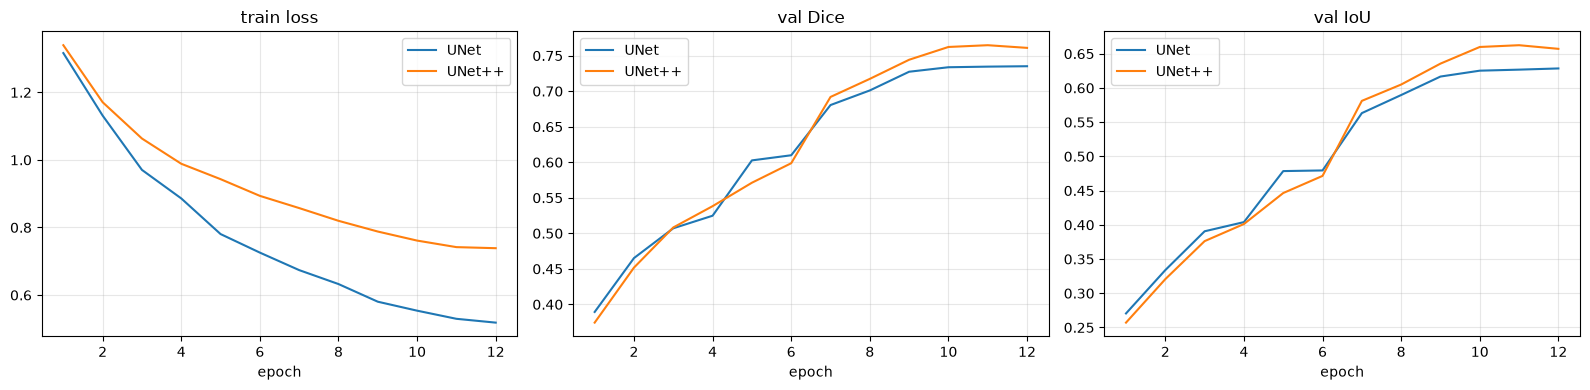

,params_M,loss,dice,iou,ms
model,,,,,
UNet,7.8496,0.5298,0.7351,0.6285,5.3517
UNet++ (L1),9.1598,1.0061,0.3888,0.2682,2.1620
UNet++ (L2),9.1598,0.8416,0.5324,0.3929,5.0596
UNet++ (L3),9.1598,0.6132,0.6954,0.5698,10.2979
UNet++ (L4),9.1598,0.4973,0.7647,0.6625,16.4109


UNet++ pruning: L1..L3 reuse the fully trained weights but stop early -> fewer FLOPs, lower latency, small Dice drop.


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for h, lab in [(hist_unet, "UNet"), (hist_unetpp, "UNet++")]:
    ep = [r["epoch"] for r in h]
    ax[0].plot(ep, [r["train_loss"] for r in h], label=lab); ax[1].plot(ep, [r["val_dice"] for r in h], label=lab); ax[2].plot(ep, [r["val_iou"] for r in h], label=lab)
for a, t in zip(ax, ["train loss", "val Dice", "val IoU"]): a.set_title(t); a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig(Path(cfg.out_dir) / "curves.png", dpi=120); plt.show()

criterion = SegLoss(cfg.num_classes)
@torch.no_grad()
def latency_ms(model, L=None, iters=20):
    model.eval(); x = torch.zeros(1, 3, cfg.img_size, cfg.img_size, device=DEVICE)
    for _ in range(3): _ = model(x, L=L) if L else model(x)
    if DEVICE == "cuda": torch.cuda.synchronize()
    t = time.time()
    for _ in range(iters): _ = model(x, L=L) if L else model(x)
    if DEVICE == "cuda": torch.cuda.synchronize()
    return (time.time() - t) / iters * 1000

rows = [dict(model="UNet", params_M=count_params(unet), **evaluate(unet, val_dl, criterion, cfg), ms=latency_ms(unet))]
for L in (1, 2, 3, 4):
    rows.append(dict(model=f"UNet++ (L{L})", params_M=count_params(unetpp), **evaluate(unetpp, val_dl, criterion, cfg, L=L), ms=latency_ms(unetpp, L=L)))
import pandas as pd
results = pd.DataFrame(rows).set_index("model").round(4); results.to_csv(Path(cfg.out_dir) / "results.csv")
display(results)
print("UNet++ pruning: L1..L3 reuse the fully trained weights but stop early -> fewer FLOPs, lower latency, small Dice drop.")

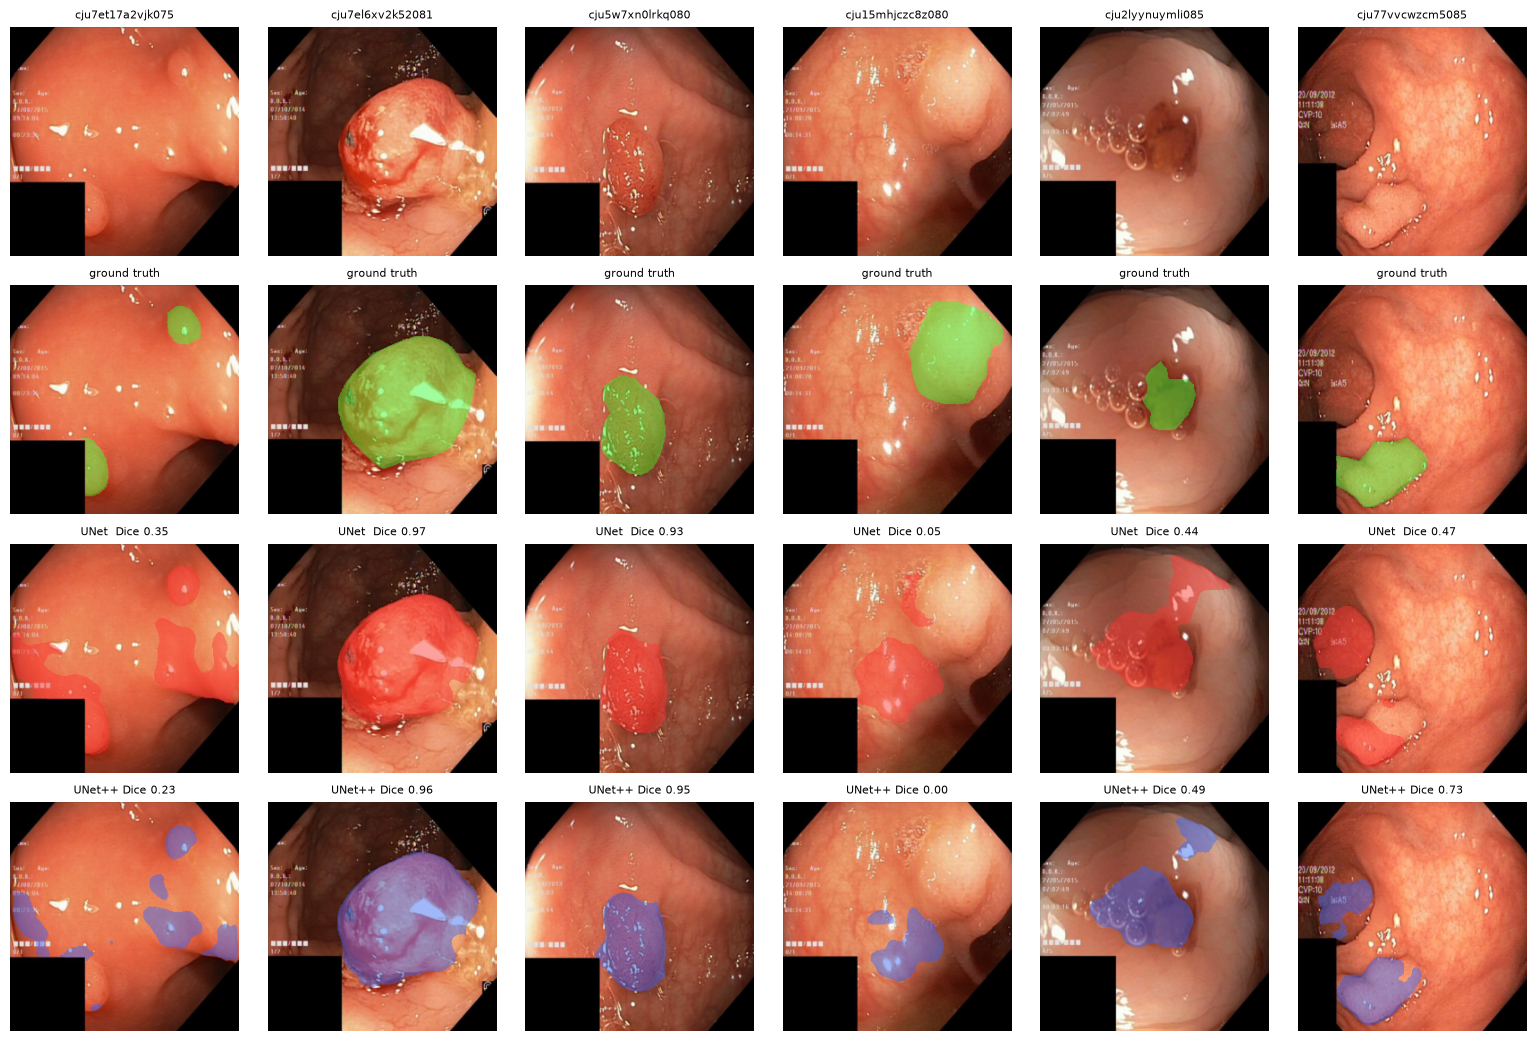

In [13]:
@torch.no_grad()
def predict_logits(model, x, L=4):
    model.eval()
    with torch.autocast(DEVICE, enabled=cfg.amp and DEVICE == "cuda"):
        out = model(x.to(DEVICE), L=L) if isinstance(model, UNetPlusPlus) else model(x.to(DEVICE))
    return out.float()

def overlay(img, mask, color=(1, 0.2, 0.2), alpha=0.45):
    img = img.copy(); m = mask.astype(bool)
    img[m] = (1 - alpha) * img[m] + alpha * np.array(color)
    return img

k = min(6, len(val_ds)); idx = np.linspace(0, len(val_ds) - 1, k).astype(int)
fig, ax = plt.subplots(4, k, figsize=(2.6 * k, 10.5))
for c, i in enumerate(idx):
    x, y = val_ds[i]; img = denorm(x).permute(1, 2, 0).numpy()
    gt = y.squeeze().numpy() if cfg.num_classes == 1 else y.numpy()
    pu = hard_pred(predict_logits(unet, x[None]), cfg.num_classes)[0].cpu().numpy()
    pp = hard_pred(predict_logits(unetpp, x[None]), cfg.num_classes)[0].cpu().numpy()
    du, _ = dice_iou(torch.tensor(pu)[None], y[None], cfg.num_classes); dp, _ = dice_iou(torch.tensor(pp)[None], y[None], cfg.num_classes)
    ax[0, c].imshow(img); ax[0, c].set_title(val_pairs[i][0].name[:16], fontsize=8)
    ax[1, c].imshow(overlay(img, gt, (0.2, 1, 0.2))); ax[1, c].set_title("ground truth", fontsize=8)
    ax[2, c].imshow(overlay(img, pu)); ax[2, c].set_title(f"UNet  Dice {du:.2f}", fontsize=8)
    ax[3, c].imshow(overlay(img, pp, (0.2, 0.4, 1))); ax[3, c].set_title(f"UNet++ Dice {dp:.2f}", fontsize=8)
    for a in ax[:, c]: a.axis("off")
plt.tight_layout(); plt.savefig(Path(cfg.out_dir) / "predictions.png", dpi=110); plt.show()

## 8. Inference on new images (any size)

`predict_image()` resizes to the training resolution, runs the network and resizes the mask back to the original resolution — use it on a single file or in a loop over a folder.

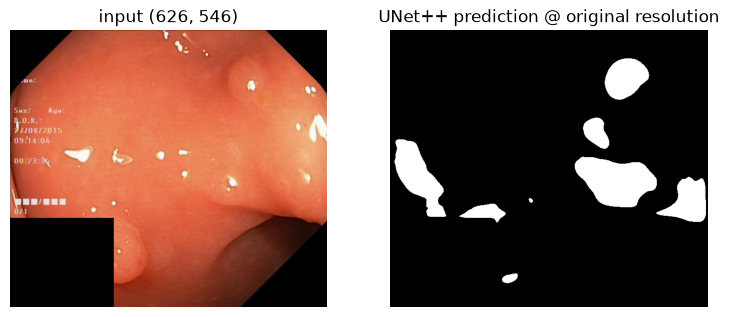

In [14]:
@torch.no_grad()
def predict_image(model, path, cfg=cfg, L=4, threshold=0.5):
    im = Image.open(path).convert("RGB"); W, H = im.size
    x = torch.from_numpy(np.asarray(im.resize((cfg.img_size, cfg.img_size), Image.BILINEAR), np.float32) / 255).permute(2, 0, 1)
    logits = predict_logits(model, ((x - 0.5) / 0.5)[None], L=L)
    logits = F.interpolate(logits, size=(H, W), mode="bilinear", align_corners=False)
    if cfg.num_classes == 1: return (torch.sigmoid(logits)[0, 0] > threshold).cpu().numpy().astype(np.uint8)
    return logits.argmax(1)[0].cpu().numpy().astype(np.uint8)

sample = val_pairs[0][0]
mask = predict_image(unetpp, sample)
Image.fromarray(mask * (255 if cfg.num_classes == 1 else 1)).save(Path(cfg.out_dir) / "sample_prediction.png")
fig, ax = plt.subplots(1, 2, figsize=(9, 4)); ax[0].imshow(Image.open(sample)); ax[0].set_title(f"input {Image.open(sample).size}"); ax[1].imshow(mask, cmap="gray"); ax[1].set_title("UNet++ prediction @ original resolution")
for a in ax: a.axis("off")
plt.show()

## 9. Using this notebook for *your* use case

1. Put images in one folder and masks in another, **same file stem** (`case_001.jpg` ↔ `case_001.png`).
   * binary problem → masks are 0/255 (or any value `> mask_threshold`) ; set `num_classes=1`
   * multi‑class → masks are single‑channel PNGs with class indices 0…K‑1 ; set `num_classes=K`
2. Edit the `Config` cell (paths, `num_classes`, `img_size`, `epochs`, `base_channels`). Examples:
   ```python
   cfg = Config(images_dir="D:/data/retina/images", masks_dir="D:/data/retina/masks", num_classes=1, img_size=512, base_channels=16)
   cfg = Config(images_dir="D:/data/drone/images", masks_dir="D:/data/drone/labels", num_classes=6, img_size=384, use_se=True)
   ```
3. Run all cells. Checkpoints (`*_best.pt`), histories, `results.csv`, `curves.png` and `predictions.png` land in `cfg.out_dir`.
4. For deployment load a checkpoint and call `predict_image()`; for speed use `UNetPlusPlus` with `L=2` or `L=3` (pruned).

**Extending**: swap `ConvBlock` for residual blocks, plug a pretrained encoder (e.g. ResNet from `torchvision`) into `UNet.enc`, change `SegLoss` (focal/Tversky for heavy class imbalance — the stroke paper's *restrictive patch sampling* addresses the same imbalance for 3D volumes), or add 3D support by replacing `nn.Conv2d/BatchNorm2d/MaxPool2d` with their 3D counterparts.